# 402 - Deep Convolutional Models: Case Studies

## Table of Contents
[1.2. Building Neural Networks with PyTorch](#Building-Neural-Networks-with-PyTorch)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.1. PyTorch Fundamentals](#PyTorch-Fundamentals)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.2. Implementing Linear Regression](#Implementing-Linear-Regression)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.3. Implementing a Regression MLP](#Implementing-a-Regression-MLP)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.4. Implementing Mini-Batch Gradient Descent Using DataLoaders](#Implementing-Mini-Batch-Gradient-Descent-Using-DataLoaders)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.5. Model Evaluation](#Model-Evaluation)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.6. Building Nonsequential Models Using Custom Modules](#Building-Nonsequential-Models-Using-Custom-Modules)<br>

<div style="background-color: #ffe6e6; border-left: 5px solid #ff4d4d; padding: 15px; border-radius: 4px; color: #333;">
  <strong>Note:</strong> Before going over this week's programming assignments, I'm going to study Chapters 10 and 11 from Geron's <i>Hands-on Machine Learning with Scikit-Learn and PyTorch.</i> To learn how to implement models using PyTorch's high-level API.
</div>

In [159]:
# Standard Imports
import numpy as np
import matplotlib.pyplot as plt
import torch

## Building Neural Networks with PyTorch

### PyTorch Fundamentals

In [4]:
# Check available devices
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'
print(device)

mps


In [210]:
# Hardware Accelarators: GPU vs CPU (Hydrogen bomb vs. coughing baby)
# CPU
M = torch.rand((1000,1000))
%timeit M @ M.T

# GPU
M = torch.rand((1000,1000), device='mps')
%timeit M @ M.T

980 μs ± 5.04 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
783 μs ± 3.54 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [81]:
# Autograd - Optimizing a quadratic function
learning_rate = 0.01
x = torch.tensor(-15., requires_grad=True, device=device)
y = torch.tensor(-19., requires_grad=True, device=device)
x_data = [x.detach().cpu()]
y_data = [y.detach().cpu()]
for iteration in range(100):
    f = x**2 + 10*y**2     # Forward
    f.backward()        # Backward

    # Update
    with torch.no_grad():
        x -= learning_rate * x.grad
        y -= learning_rate * y.grad

    # Log data
    x_data.append(x.detach().cpu())
    y_data.append(y.detach().cpu())

    # Reset grads
    x.grad.zero_()
    y.grad.zero_()

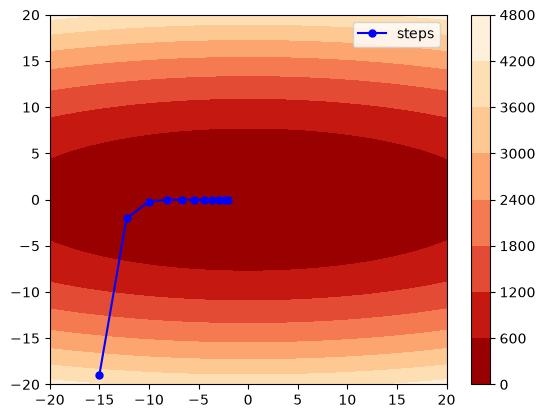

In [101]:
# Plot results
N = 100
xx = np.linspace(-20.0, 20.0, N)
yy = np.linspace(-20.0, 20.0, N)
XX, YY = np.meshgrid(xx, yy)
z = XX**2 + 10*YY**2
fig, ax = plt.subplots()
cs = ax.contourf(XX, YY, z, cmap="OrRd_r")
cbar = fig.colorbar(cs)

ax.plot(x_data[::10], y_data[::10], marker='o', ms = 5, linestyle='-', color='blue', label='steps')
ax.legend()
plt.show()

### Implementing Linear Regression

In [110]:
# Data - California Housing
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from pathlib import Path
X, y = fetch_california_housing(data_home=Path.cwd().joinpath('data'),
                                download_if_missing=True,
                                return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, random_state=42)

print('X_train shape:', X_train.shape)
print('y_train shape:', y_train.shape)
print('X_val shape:', X_val.shape)
print('y_val shape:', y_val.shape)
print('X_test shape:', X_test.shape)
print('y_test shape:', y_test.shape)

X_train shape: (11610, 8)
y_train shape: (11610,)
X_val shape: (3870, 8)
y_val shape: (3870,)
X_test shape: (5160, 8)
y_test shape: (5160,)


In [116]:
# Preprocessing - Tensorize and Scale
X_train = torch.FloatTensor(X_train)
X_val = torch.FloatTensor(X_val)
X_test = torch.FloatTensor(X_test)
means = X_train.mean(dim=0, keepdim=True)
stds = X_train.std(dim=0, keepdim=True)
X_train = (X_train - means) / stds
X_val = (X_val - means) / stds
X_test = (X_test - means) / stds

y_train = torch.FloatTensor(y_train).reshape(-1,1)
y_val = torch.FloatTensor(y_val).reshape(-1,1)
y_test = torch.FloatTensor(y_test).reshape(-1,1)

print(f'X_train means (are all close to zero?):', torch.allclose(X_train.mean(), torch.tensor(0.0)))
print('X_train std (are all close to one?):', torch.allclose(X_train.std(dim=0), torch.tensor(1.0)))
print('y_train shape:', y_train.shape)
print('y_val shape:', y_val.shape)
print('y_test shape:', y_test.shape)

X_train means (are all close to zero?): True
X_train std (are all close to one?): True
y_train shape: torch.Size([11610, 1])
y_val shape: torch.Size([3870, 1])
y_test shape: torch.Size([5160, 1])


#### Using Tensors and Autograd

In [144]:
# Initialize Parameters
torch.manual_seed(42)
n_in = X_train.shape[1]
W = torch.randn((n_in, 1), requires_grad=True, device=device)
b = torch.tensor(0., requires_grad=True, device=device)

print('W.shape:', W.shape)
print('b.shape:', b.shape)
print('W\n', W)
print('b\n', b)

W.shape: torch.Size([8, 1])
b.shape: torch.Size([])
W
 tensor([[ 1.7563],
        [-0.2539],
        [-0.9927],
        [-0.6515],
        [-0.4827],
        [-0.1972],
        [ 0.4944],
        [ 0.2693]], device='mps:0', requires_grad=True)
b
 tensor(0., device='mps:0', requires_grad=True)


In [145]:
# Training
learning_rate = 0.4
epochs = 20

for iteration in range(epochs):
    # Forward
    y_train_pred = torch.matmul(X_train.to(device), W) + b
    mse_cost = ((y_train_pred - y_train.to(device))**2).mean(dim=0, keepdim=True)

    # Backward
    mse_cost.backward()

    with torch.no_grad():
        # Weight update
        W -= learning_rate * W.grad
        b -= learning_rate * b.grad

        # Reset grads
        W.grad.zero_()
        b.grad.zero_()

    print(f"Epoch {iteration + 1}/{epochs}, MSE: {mse_cost.item()}")

Epoch 1/20, MSE: 7.979630470275879
Epoch 2/20, MSE: 1.3271340131759644
Epoch 3/20, MSE: 0.8188687562942505
Epoch 4/20, MSE: 0.7123928666114807
Epoch 5/20, MSE: 0.6727661490440369
Epoch 6/20, MSE: 0.6517986059188843
Epoch 7/20, MSE: 0.6373873949050903
Epoch 8/20, MSE: 0.6258752346038818
Epoch 9/20, MSE: 0.6160195469856262
Epoch 10/20, MSE: 0.6073315143585205
Epoch 11/20, MSE: 0.5995773077011108
Epoch 12/20, MSE: 0.5926181077957153
Epoch 13/20, MSE: 0.5863552093505859
Epoch 14/20, MSE: 0.5807100534439087
Epoch 15/20, MSE: 0.5756163001060486
Epoch 16/20, MSE: 0.5710160136222839
Epoch 17/20, MSE: 0.566858172416687
Epoch 18/20, MSE: 0.5630974769592285
Epoch 19/20, MSE: 0.5596936345100403
Epoch 20/20, MSE: 0.5566105842590332


In [146]:
# Validation and Test
with torch.no_grad():
    y_val_pred = torch.matmul(X_val, W.cpu()) + b.cpu()
    mse_val = ((y_val_pred - y_val)**2).mean(dim=0, keepdim=True)
    print(f'Validation MSE: {mse_val.item():.3f}')

    y_test_pred = torch.matmul(X_test, W.cpu()) + b.cpu()
    mse_test = ((y_test_pred - y_test)**2).mean(dim=0, keepdim=True)
    print(f'Test MSE: {mse_test.item():.3f}')

Validation MSE: 1.179
Test MSE: 0.563


#### Using PyTorch's High-Level API

In [154]:
# Instantiation of Module
import torch.nn as nn
torch.manual_seed(42)
model = nn.Linear(in_features=n_in, out_features=1, bias=True)

print(model.bias)
print(model.weight)

# Sample prediction
print('prediction:\n', model(X_train[:2]))
print('actual:\n', y_train[:2])

Parameter containing:
tensor([0.3117], requires_grad=True)
Parameter containing:
tensor([[ 0.2703,  0.2935, -0.0828,  0.3248, -0.0775,  0.0713, -0.1721,  0.2076]],
       requires_grad=True)
prediction:
 tensor([[-0.4718],
        [ 0.1131]], grad_fn=<AddmmBackward0>)
actual:
 tensor([[1.4420],
        [1.6870]])


In [155]:
# Training
def train_bgd(model, optimizer, criterion, X_train, y_train, n_epochs):
    for epoch in range(n_epochs):
        y_pred = model(X_train)
        loss = criterion(y_pred, y_train)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        print(f'Epoch {epoch + 1}/{n_epochs}, Loss: {loss.item()}')

optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
mse = nn.MSELoss()
train_bgd(model, optimizer, mse, X_train, y_train, 20)

Epoch 1/20, Loss: 4.3378520011901855
Epoch 2/20, Loss: 0.7802940607070923
Epoch 3/20, Loss: 0.6253843307495117
Epoch 4/20, Loss: 0.6060435175895691
Epoch 5/20, Loss: 0.5956299304962158
Epoch 6/20, Loss: 0.587356686592102
Epoch 7/20, Loss: 0.5802989602088928
Epoch 8/20, Loss: 0.5741382241249084
Epoch 9/20, Loss: 0.5687100291252136
Epoch 10/20, Loss: 0.5639079213142395
Epoch 11/20, Loss: 0.5596510767936707
Epoch 12/20, Loss: 0.5558737516403198
Epoch 13/20, Loss: 0.5525193810462952
Epoch 14/20, Loss: 0.5495391488075256
Epoch 15/20, Loss: 0.5468899011611938
Epoch 16/20, Loss: 0.544533908367157
Epoch 17/20, Loss: 0.5424376726150513
Epoch 18/20, Loss: 0.5405715703964233
Epoch 19/20, Loss: 0.5389097332954407
Epoch 20/20, Loss: 0.5374288558959961


In [157]:
# Validation and Test
with torch.no_grad():
    y_val_pred = model(X_val)
    mse_val = mse(y_val_pred, y_val)
    print(f'Validation MSE: {mse_val.item():.3f}')

    y_test_pred = model(X_test)
    mse_test = mse(y_test_pred, y_test)
    print(f'Test MSE: {mse_test.item():.3f}')

Validation MSE: 1.169
Test MSE: 0.538


### Implementing a Regression MLP

In [161]:
# Instantiate model, optimizer, and loss function
torch.manual_seed(42)
learning_rate = 0.1
model = nn.Sequential(
    nn.Linear(n_in, 50),
    nn.ReLU(),
    nn.Linear(50, 40),
    nn.ReLU(),
    nn.Linear(40, 1),
)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
mse = nn.MSELoss()

In [162]:
# Training
train_bgd(model, optimizer, mse, X_train, y_train, 20)

Epoch 1/20, Loss: 5.045480251312256
Epoch 2/20, Loss: 2.0523130893707275
Epoch 3/20, Loss: 1.0039886236190796
Epoch 4/20, Loss: 0.857014000415802
Epoch 5/20, Loss: 0.7740675210952759
Epoch 6/20, Loss: 0.7225848436355591
Epoch 7/20, Loss: 0.6893725991249084
Epoch 8/20, Loss: 0.6669032573699951
Epoch 9/20, Loss: 0.650773823261261
Epoch 10/20, Loss: 0.6383934020996094
Epoch 11/20, Loss: 0.6281994581222534
Epoch 12/20, Loss: 0.6193400025367737
Epoch 13/20, Loss: 0.6113174557685852
Epoch 14/20, Loss: 0.6038705706596375
Epoch 15/20, Loss: 0.5968309044837952
Epoch 16/20, Loss: 0.5901119709014893
Epoch 17/20, Loss: 0.5836468935012817
Epoch 18/20, Loss: 0.5774064064025879
Epoch 19/20, Loss: 0.5713556408882141
Epoch 20/20, Loss: 0.5654448866844177


In [163]:
# Validation and Testing
with torch.no_grad():
    y_val_pred = model(X_val)
    mse_val = mse(y_val_pred, y_val)
    print(f'Validation MSE: {mse_val.item():.3f}')
    y_test_pred = model(X_test)
    mse_test = mse(y_test_pred, y_test)
    print(f'Test MSE: {mse_test.item():.3f}')

Validation MSE: 0.528
Test MSE: 0.550


### Implementing Mini-Batch Gradient Descent Using DataLoaders
For PyTorch's `torch.utils.data.DataLoader` to work, the dataset must have at least two methods: `__len__(self)` and `__getitem__(self, index)`. Tensors have these.

In [169]:
# Check dataset attributes
print('X_train has __len__ method:', hasattr(X_train, '__len__'))
print('X_train has __getitem__ method:', hasattr(X_train, '__getitem__'))

X_train has __len__ method: True
X_train has __getitem__ method: True


In [170]:
# Wrapping in dataset object and creating data loader
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

In [177]:
# Training with Minibatch GD
torch.manual_seed(42)
learning_rate = 0.02
model = nn.Sequential(
    nn.Linear(n_in, 50),
    nn.ReLU(),
    nn.Linear(50, 40),
    nn.ReLU(),
    nn.Linear(40, 1),
).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
mse = nn.MSELoss()

def train_mbgd(model, dataloader, optimizer, criterion, n_epochs, device='mps'):
    model.train()   # Training mode??? idk...
    training_loss = 0
    for epoch in range(n_epochs):
        for X_mb, y_mb in dataloader:
            X_mb = X_mb.to(device)
            y_mb = y_mb.to(device)
            y_out = model(X_mb)
            loss = criterion(y_out, y_mb)
            training_loss += loss.detach().item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        training_loss /= len(dataloader)
        print(f'Epoch {epoch + 1}/{n_epochs}, Loss: {training_loss}')

train_mbgd(model, train_loader, optimizer, mse, 20, device)

Epoch 1/20, Loss: 0.5900079238102784
Epoch 2/20, Loss: 0.40617793351074827
Epoch 3/20, Loss: 0.3812409350448311
Epoch 4/20, Loss: 0.3639697381641072
Epoch 5/20, Loss: 0.35405540368439453
Epoch 6/20, Loss: 0.35315823936488355
Epoch 7/20, Loss: 0.3418332261469417
Epoch 8/20, Loss: 0.3421076757021259
Epoch 9/20, Loss: 0.34126834015059937
Epoch 10/20, Loss: 0.3446410464446847
Epoch 11/20, Loss: 0.3318698472562356
Epoch 12/20, Loss: 0.3272509280538928
Epoch 13/20, Loss: 0.3250868026762233
Epoch 14/20, Loss: 0.3227055189788914
Epoch 15/20, Loss: 0.31980858085508534
Epoch 16/20, Loss: 0.31709102038586096
Epoch 17/20, Loss: 0.31348098657112705
Epoch 18/20, Loss: 0.3110350068235524
Epoch 19/20, Loss: 0.3088778259000568
Epoch 20/20, Loss: 0.31138984235074163


In [176]:
# Validation and Testing
with torch.no_grad():
    y_val_pred = model.to('cpu')(X_val)
    mse_val = mse(y_val_pred, y_val)
    print(f'Validation MSE: {mse_val.item():.3f}')
    y_test_pred = model.to('cpu')(X_test)
    mse_test = mse(y_test_pred, y_test)
    print(f'Test MSE: {mse_test.item():.3f}')

Validation MSE: 0.307
Test MSE: 0.314


### Model Evaluation

In [194]:
# Define Evaluator
from collections.abc import Callable

def evaluate(model, loader, metric_fn, agg_fn: Callable = torch.mean, device='mps'):
    model.eval()
    metrics = []
    with torch.no_grad():
        for X_mb, y_mb in loader:
            X_mb, y_mb = X_mb.to(device), y_mb.to(device)
            y_pred = model(X_mb)
            metric = metric_fn(y_pred, y_mb)
            metrics.append(metric)
    return agg_fn(torch.stack(metrics))

In [196]:
# Build Validation Dataset
val_dataset = TensorDataset(X_val, y_val)
val_loader = DataLoader(val_dataset, batch_size=32)

In [197]:
# Validation with MSE
val_mse = evaluate(model, val_loader, mse)
print(f'Validation MSE: {val_mse.item():.3f}')

Validation MSE: 0.307


In [198]:
# Validation with RMSE
val_rmse = evaluate(model, val_loader, mse, lambda metrics: torch.sqrt(torch.mean(metrics)))
print(f'Validation RMSE: {val_rmse.item():.3f}')

Validation RMSE: 0.554


In [208]:
# Implementation with TorchMetrics
from torchmetrics import MeanSquaredError, Metric

def evaluate_tm(model, loader, metric_fn: Metric, device='mps'):
    model.eval()
    metric_fn.reset()
    with torch.no_grad():
        for X_mb, y_mb in loader:
            X_mb, y_mb = X_mb.to(device), y_mb.to(device)
            y_pred = model(X_mb)
            metric_fn.update(y_pred, y_mb)
    return metric_fn.compute()

# with MSE
mse_tm = MeanSquaredError().to(device)
val_mse = evaluate_tm(model, val_loader, mse_tm)

# with RMSE
rmse_tm = MeanSquaredError(squared=False).to(device)
val_rmse = evaluate_tm(model, val_loader, rmse_tm)

print(f'Validation MSE: {val_mse.item():.3f}')
print(f'Validation RMSE: {val_rmse.item():.3f}')

Validation MSE: 0.307
Validation RMSE: 0.554


### Building Nonsequential Models Using Custom Modules